In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

%matplotlib inline

In [3]:
df = pd.read_csv('data/airbnb.csv')
print("Размер выборки:", df.shape)
df.head()

Размер выборки: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.drop(['id', 'name', 'host_id', 'host_name', 'last_review'], axis=1, inplace=True)
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


- neighbourhood_group — группа районов
- neighbourhood — район
- latitude — широта
- longitude — долгота
- room_type — тип жилья / тип комнаты
- price — цена
- minimum_nights — минимальное количество ночей
- number_of_reviews — количество отзывов
- reviews_per_month — количество отзывов в месяц
- calculated_host_listings_count — количество объектов у одного хоста
- availability_365 — доступность в году (дней)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   neighbourhood                   48895 non-null  object 
 2   latitude                        48895 non-null  float64
 3   longitude                       48895 non-null  float64
 4   room_type                       48895 non-null  object 
 5   price                           48895 non-null  int64  
 6   minimum_nights                  48895 non-null  int64  
 7   number_of_reviews               48895 non-null  int64  
 8   reviews_per_month               38843 non-null  float64
 9   calculated_host_listings_count  48895 non-null  int64  
 10  availability_365                48895 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 4.1+ MB


In [6]:
df.isnull().sum()

neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

<Axes: >

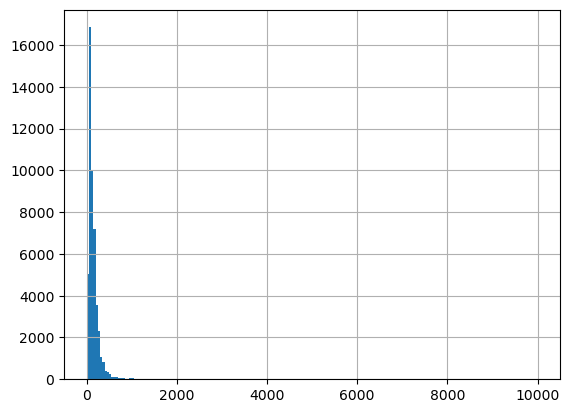

In [7]:
df.price.hist(bins=200)

<Axes: >

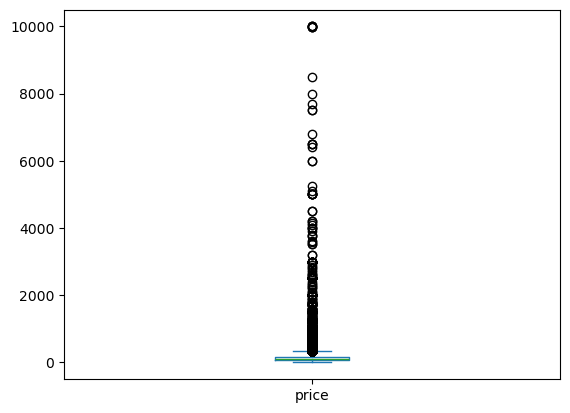

In [8]:
df.price.plot.box()

<Axes: >

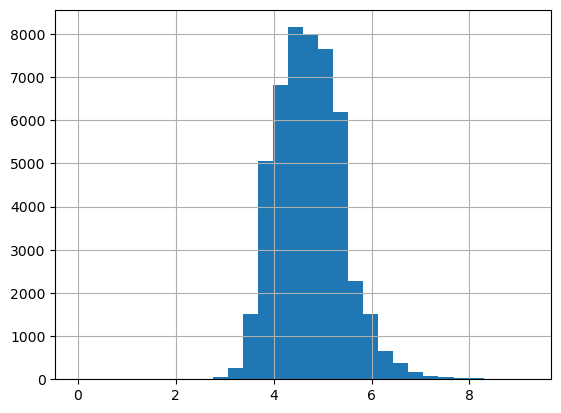

In [9]:
df['price'] = np.log1p(df['price']) # прологорифмировал целевую, потому что данные скошены влево
df.price.hist(bins=30)

<Axes: >

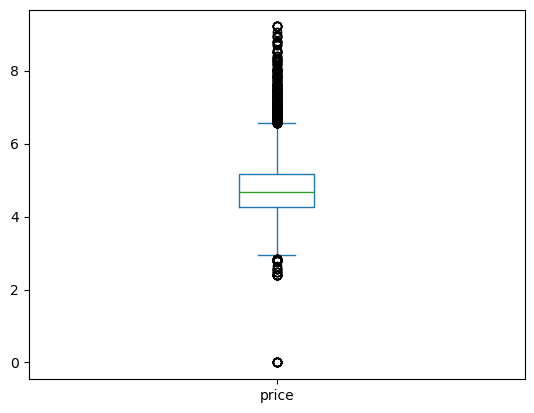

In [10]:
df.price.plot.box()

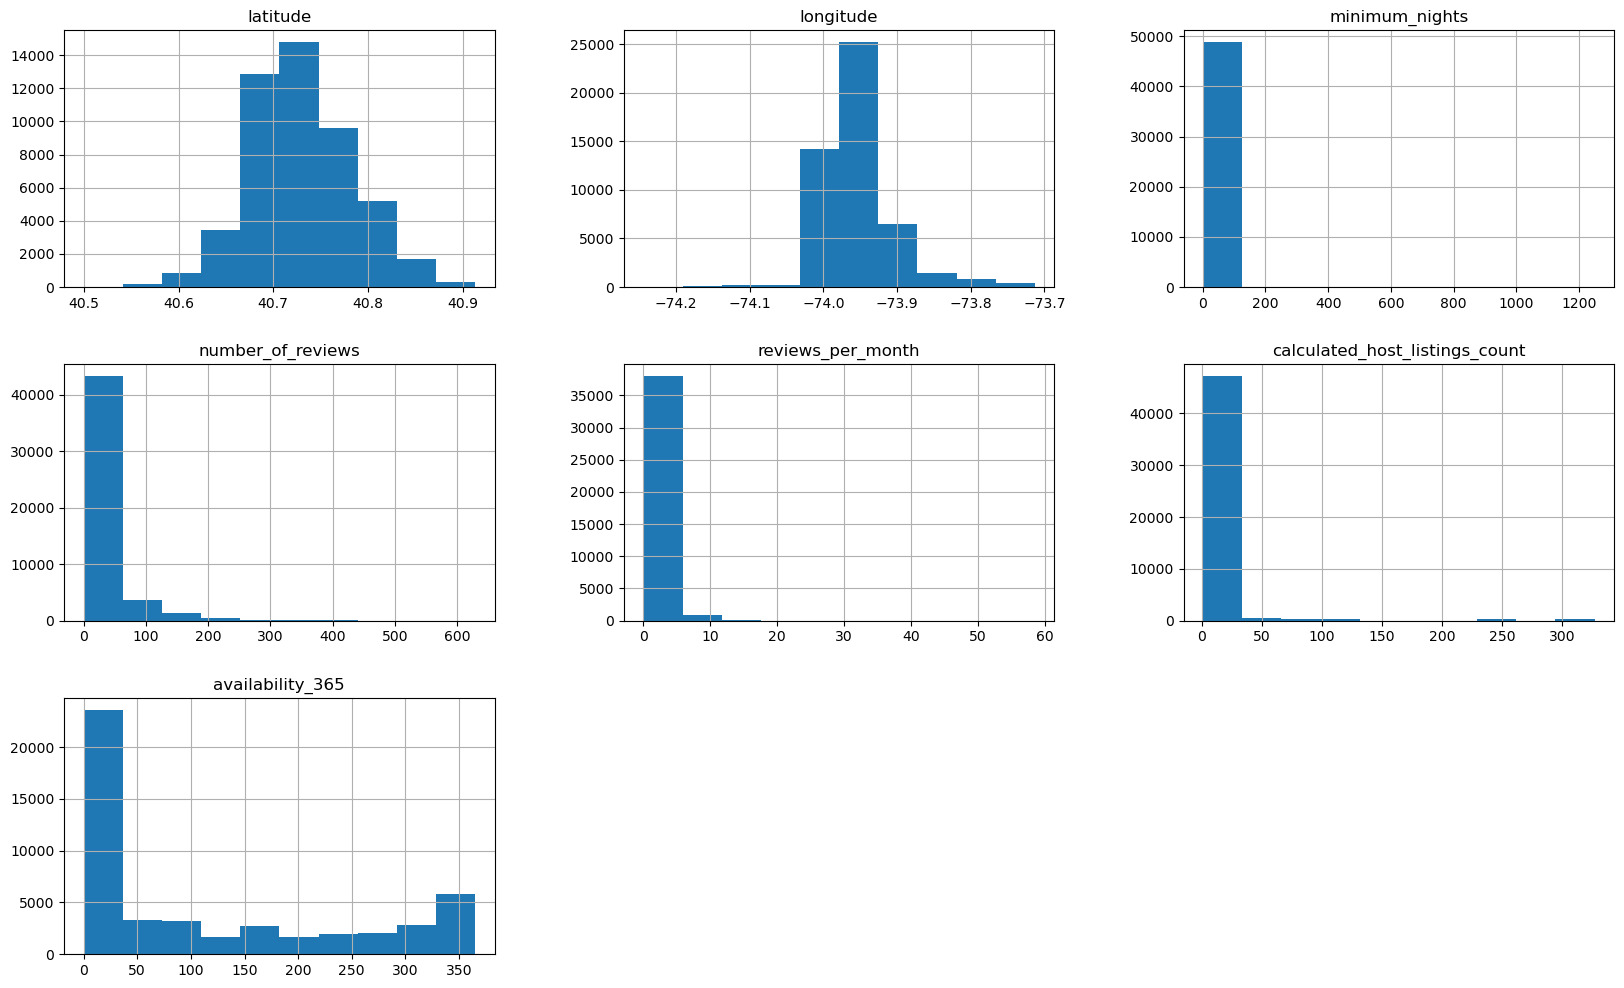

In [11]:
df.drop('price', axis=1).hist(figsize=(20,12));

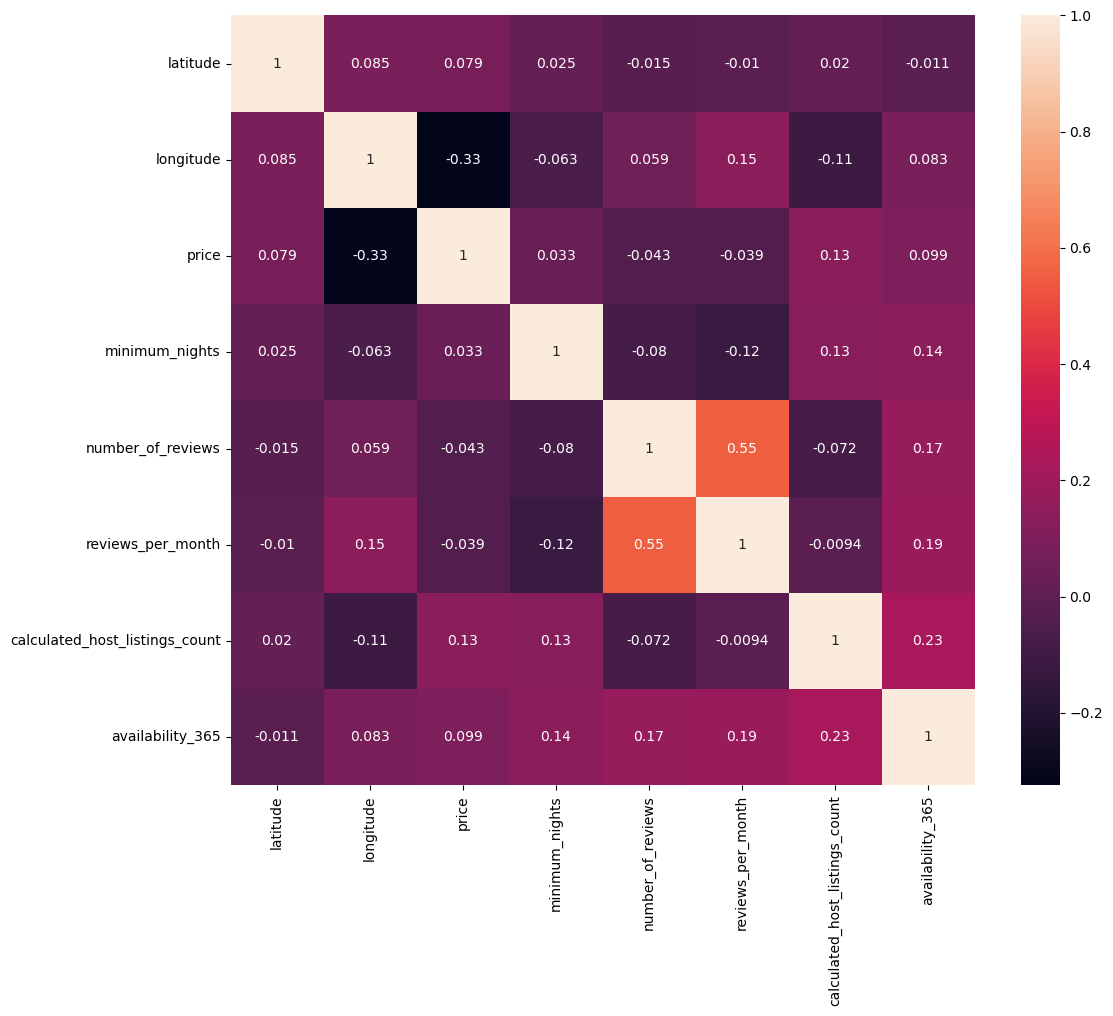

In [12]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(numeric_only=True), annot=True);

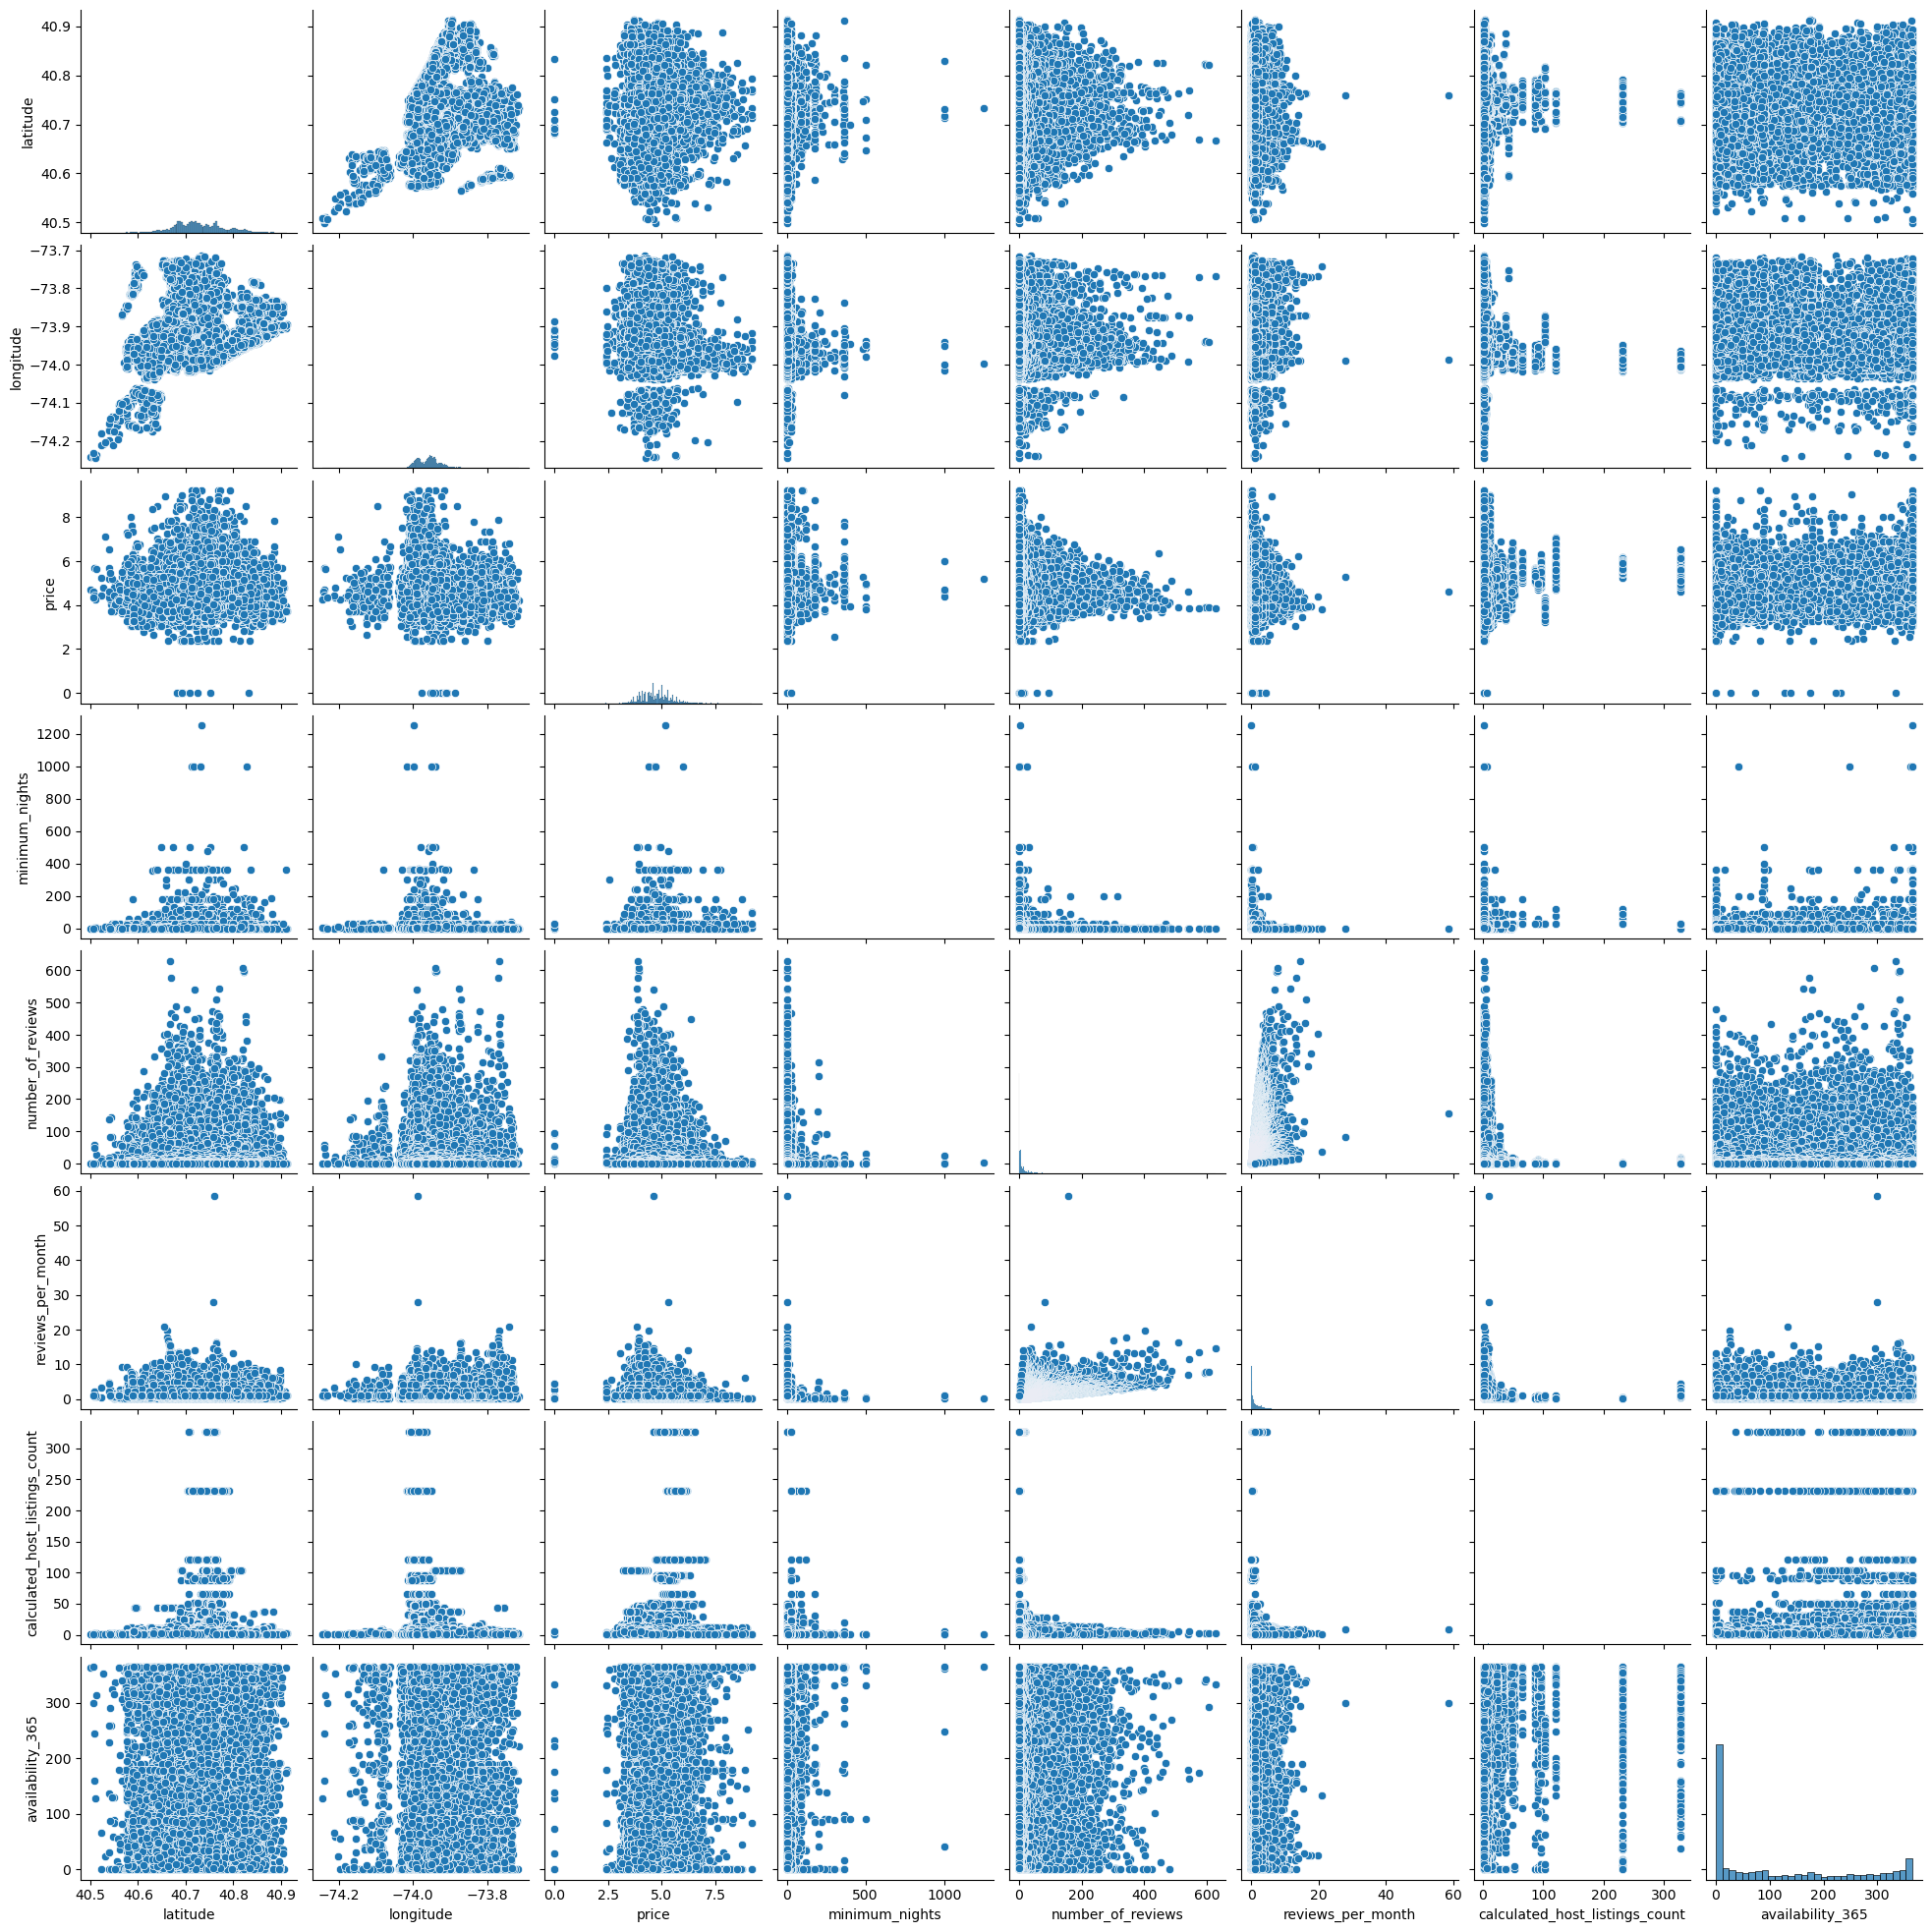

In [80]:
sns.pairplot(df)

In [13]:
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,5.010635,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,5.420535,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,5.017280,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,4.499810,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,4.394449,10,9,0.10,1,0


In [14]:
df.neighbourhood_group.unique()

array(['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx'],
      dtype=object)

In [15]:
df = pd.get_dummies(df, columns=['neighbourhood_group'], dtype=int)

In [16]:
df.head()

,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island
0,Kensington,40.64749,-73.97237,Private room,5.010635,1,9,0.21,6,365,0,1,0,0,0
1,Midtown,40.75362,-73.98377,Entire home/apt,5.420535,1,45,0.38,2,355,0,0,1,0,0
2,Harlem,40.80902,-73.94190,Private room,5.017280,3,0,NaN,1,365,0,0,1,0,0
3,Clinton Hill,40.68514,-73.95976,Entire home/apt,4.499810,1,270,4.64,1,194,0,1,0,0,0
4,East Harlem,40.79851,-73.94399,Entire home/apt,4.394449,10,9,0.10,1,0,0,0,1,0,0


In [17]:
df = pd.get_dummies(df, columns=['neighbourhood', 'room_type'], dtype=int)

In [18]:
df.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,...,neighbourhood_Williamsburg,neighbourhood_Willowbrook,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodlawn,neighbourhood_Woodrow,neighbourhood_Woodside,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,5.010635,1,9,0.21,6,365,0,1,...,0,0,0,0,0,0,0,0,1,0
1,40.75362,-73.98377,5.420535,1,45,0.38,2,355,0,0,...,0,0,0,0,0,0,0,1,0,0
2,40.80902,-73.94190,5.017280,3,0,NaN,1,365,0,0,...,0,0,0,0,0,0,0,0,1,0
3,40.68514,-73.95976,4.499810,1,270,4.64,1,194,0,1,...,0,0,0,0,0,0,0,1,0,0
4,40.79851,-73.94399,4.394449,10,9,0.10,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [19]:
center_lat = 40.7128
center_lon = -74.0060

df['center_distance'] = np.sqrt(
    (df['latitude'] - center_lat)**2 + (df['longitude'] - center_lon)**2
)

df = df.drop(columns=['latitude', 'longitude'])

In [20]:
df.head()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,...,neighbourhood_Willowbrook,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodlawn,neighbourhood_Woodrow,neighbourhood_Woodside,room_type_Entire home/apt,room_type_Private room,room_type_Shared room,center_distance
0,5.010635,1,9,0.21,6,365,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0.073460
1,5.420535,1,45,0.38,2,355,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0.046481
2,5.017280,3,0,NaN,1,365,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0.115616
3,4.499810,1,270,4.64,1,194,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0.053881
4,4.394449,10,9,0.10,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0.105790


In [21]:
df.isna().sum()

price                                 0
minimum_nights                        0
number_of_reviews                     0
reviews_per_month                 10052
calculated_host_listings_count        0
                                  ...  
neighbourhood_Woodside                0
room_type_Entire home/apt             0
room_type_Private room                0
room_type_Shared room                 0
center_distance                       0
Length: 236, dtype: int64

In [22]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df.isna().sum()

price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
                                 ..
neighbourhood_Woodside            0
room_type_Entire home/apt         0
room_type_Private room            0
room_type_Shared room             0
center_distance                   0
Length: 236, dtype: int64

In [23]:
df = df.dropna(subset=['price'])
print(df['price'].isna().sum())

0


In [24]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.3)

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(df_train[['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'center_distance']]) 

,copy,True
,with_mean,True
,with_std,True


In [26]:
df_train_scale = scaler.transform(df_train[['minimum_nights', 'number_of_reviews', 'reviews_per_month', 
                                            'calculated_host_listings_count', 'availability_365', 'center_distance']])

df_test_scale = scaler.transform(df_test[['minimum_nights', 'number_of_reviews', 'reviews_per_month', 
                                           'calculated_host_listings_count', 'availability_365', 'center_distance']])

In [27]:
df_train[['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'center_distance']] = df_train_scale
df_test[['minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'center_distance']] = df_test_scale

In [28]:
df_train.head()

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,...,neighbourhood_Willowbrook,neighbourhood_Windsor Terrace,neighbourhood_Woodhaven,neighbourhood_Woodlawn,neighbourhood_Woodrow,neighbourhood_Woodside,room_type_Entire home/apt,room_type_Private room,room_type_Shared room,center_distance
46102,5.686975,-0.189109,-0.410850,2.062601,-0.187886,-0.373256,0,0,1,0,...,0,0,0,0,0,0,1,0,0,-0.833990
723,4.605170,-0.235678,-0.073845,-0.314836,-0.187886,-0.115350,0,1,0,0,...,0,0,0,0,0,0,0,1,0,-0.197261
8188,4.382027,-0.282248,-0.523185,-0.682032,-0.187886,-0.858725,0,0,1,0,...,0,0,0,0,0,0,0,1,0,1.049487
4510,5.017280,-0.282248,-0.478251,-0.563783,-0.157652,-0.198790,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0.982478
29561,5.170484,-0.142539,-0.343449,-0.364626,-0.157652,0.354948,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0.843899


In [29]:
print(df_train.shape)
print(df_test.shape)

(34226, 236)
(14669, 236)


In [30]:
y_train = df_train.price
y_test = df_test.price

X_train = df_train.drop('price', axis=1).values
X_test = df_test.drop('price', axis=1).values

# Константный прогноз

In [31]:
y_mean = np.mean(y_train)
y_pred_naive = np.ones(len(y_test)) * y_mean
y_pred_naive[:5]

array([4.73799724, 4.73799724, 4.73799724, 4.73799724, 4.73799724])

In [32]:
np.exp(4.74147039)

np.float64(114.60258835266853)

# Метрики качества

In [33]:
from sklearn import metrics

### MAE

In [43]:
metrics.mean_absolute_error(np.exp(y_test), np.exp(y_pred_naive)) # В среднем наш конст. прогноз ошибается на 83.3$

83.2875900845542

### MSE

In [35]:
metrics.mean_squared_error(y_test, y_pred_naive)

0.48499914855280374

In [36]:
metrics.mean_squared_error(np.exp(y_test), np.exp(y_pred_naive))

54974.823351374915

### RMSE

In [40]:
np.sqrt(metrics.mean_squared_error(np.exp(y_test), np.exp(y_pred_naive))) # В среднем наш конст. прогноз ошибается на 234.4$

np.float64(234.4671050518066)

#### MAPE (Mean Absolute Percentage Error)

In [41]:
metrics.mean_absolute_percentage_error(np.exp(y_test), np.exp(y_pred_naive))*100 # В среднем наш конст. прогноз ошибается на 64.5%

64.52175839891673

### $R^2$

In [42]:
metrics.r2_score(y_test, y_pred_naive) # В среднем наш конст. прогноз объясняет -2% аномалий в данных о ценах

-2.835458214356379e-05

In [44]:
def print_metrics(y_test, y_pred):
    print('MAE: ', metrics.mean_absolute_error(np.exp(y_test), np.exp(y_pred)))
    print('RMSE: ', np.sqrt(metrics.mean_squared_error(np.exp(y_test), np.exp(y_pred))))
    print("R2: ", metrics.r2_score(y_test, y_pred))
    print("MAPE: ", metrics.mean_absolute_percentage_error(np.exp(y_test), np.exp(y_pred))*100)

In [45]:
print_metrics(y_test, y_pred_naive)

MAE:  83.2875900845542
RMSE:  234.4671050518066
R2:  -2.835458214356379e-05
MAPE:  64.52175839891673


# Линейная Регрессия

In [59]:
from sklearn.linear_model import LinearRegression

In [60]:
model_regression = LinearRegression()

model_regression.fit(X_train, y_train)

y_pred_regr = model_regression.predict(X_test)

In [61]:
print_metrics(y_test, y_pred_regr)

MAE:  60.16206411711348
RMSE:  218.0554956956458
R2:  0.5341985174183872
MAPE:  37.39519447305273


In [62]:
model_regression.coef_

array([-4.18559414e-02, -2.75595094e-02, -6.31313524e-03, -1.81798727e-02,
        1.02879486e-01,  4.77405008e-02, -2.77284128e-01, -3.10000534e-02,
        2.10320506e-01,  5.02231748e-02,  5.55342296e-02, -7.61277215e-02,
       -3.67323259e-01,  4.71327267e-01, -4.19651036e-01, -1.41978332e-01,
        4.96405813e-02, -7.16756473e-02,  5.57946235e-01,  4.79382144e-01,
        1.86533256e-01,  2.77254833e-01,  3.19668772e-01, -1.22500003e-01,
        4.28246979e-01,  5.02358578e-01, -1.91623903e-02, -1.89180100e-01,
        2.33674019e-01, -5.76564538e-03, -3.40618684e-01,  1.40166635e+00,
       -1.62007525e-02,  2.41585888e-01, -2.60682407e-01,  6.31926319e-02,
       -8.61163080e-02, -2.24510651e-01, -9.80322911e-02,  3.93289850e-01,
        1.89363803e-02,  2.43300649e-02, -3.20465583e-01,  7.28940003e-02,
        5.97647356e-02, -2.90780721e-01,  6.59392088e-01, -2.56327293e-01,
       -1.77691236e-01,  8.48324703e-02, -3.77053272e-01,  4.65518426e-02,
        3.85354613e-01,  

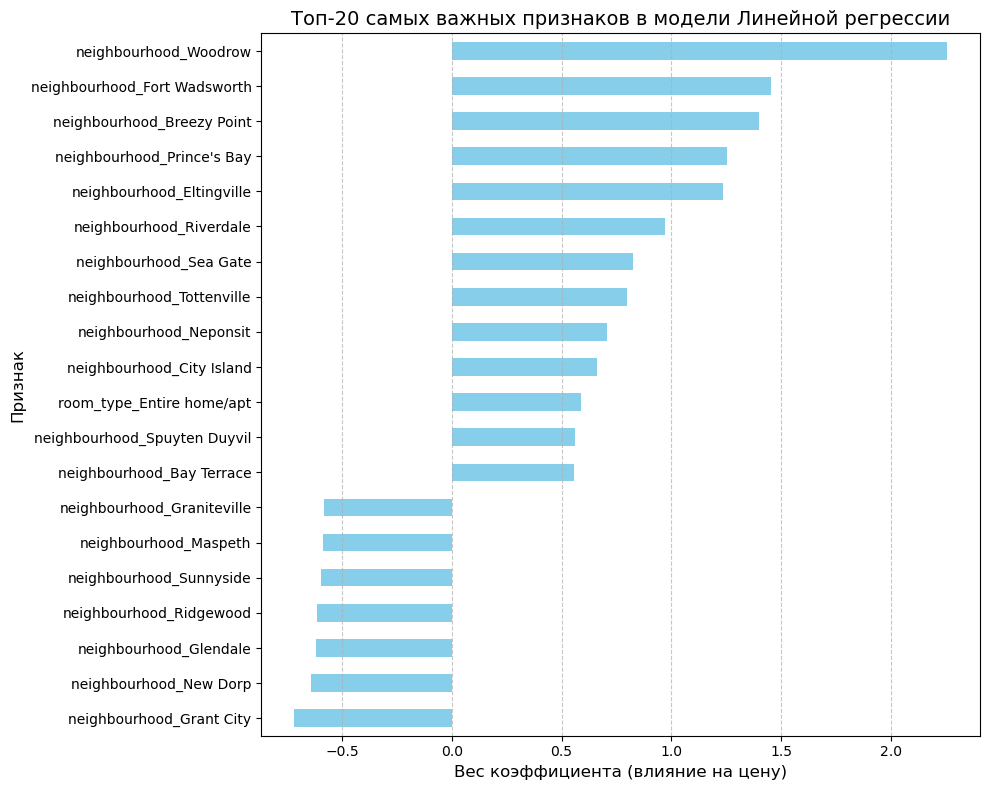

In [68]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': model_regression.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Линейной регрессии', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()


# Lasso-регрессия

In [56]:
from sklearn.linear_model import Lasso

In [71]:
model_simplelasso = Lasso()

model_simplelasso.fit(X_train, y_train)

y_pred_lasso = model_simplelasso.predict(X_test)

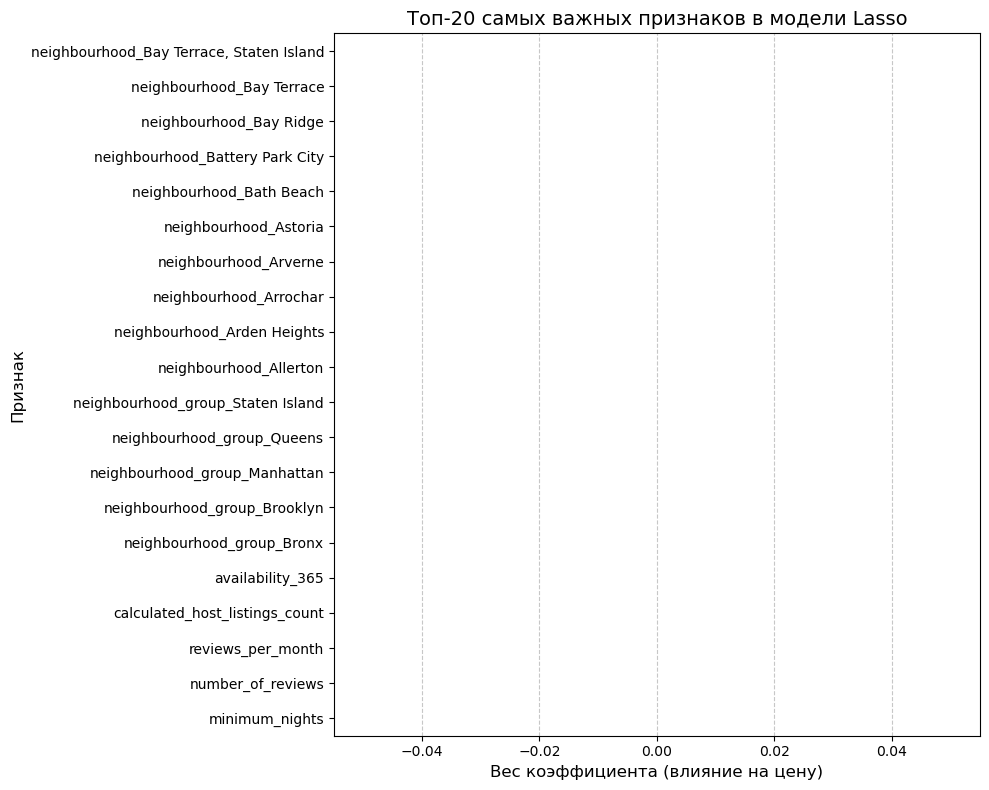

In [72]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': model_simplelasso.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Lasso', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()


In [73]:
print_metrics(y_test, y_pred_lasso)

MAE:  83.2875900845542
RMSE:  234.4671050518066
R2:  -2.835458214356379e-05
MAPE:  64.52175839891673


# Подбор гиперпараметров

In [74]:
from sklearn.model_selection import GridSearchCV

In [75]:
param_grid = {'alpha': [0.001, 0.01, 0.05, 0.1, 0.5, 0.8, 1]}

model_lasso = Lasso()

grid_cv_lasso = GridSearchCV(model_lasso, param_grid, cv=5)
grid_cv_lasso.fit(X_train, y_train)
print('Лучшее значение параметра: ', grid_cv_lasso.best_params_)

y_pred_lasso = grid_cv_lasso.predict(X_test)

Лучшее значение параметра:  {'alpha': 0.001}


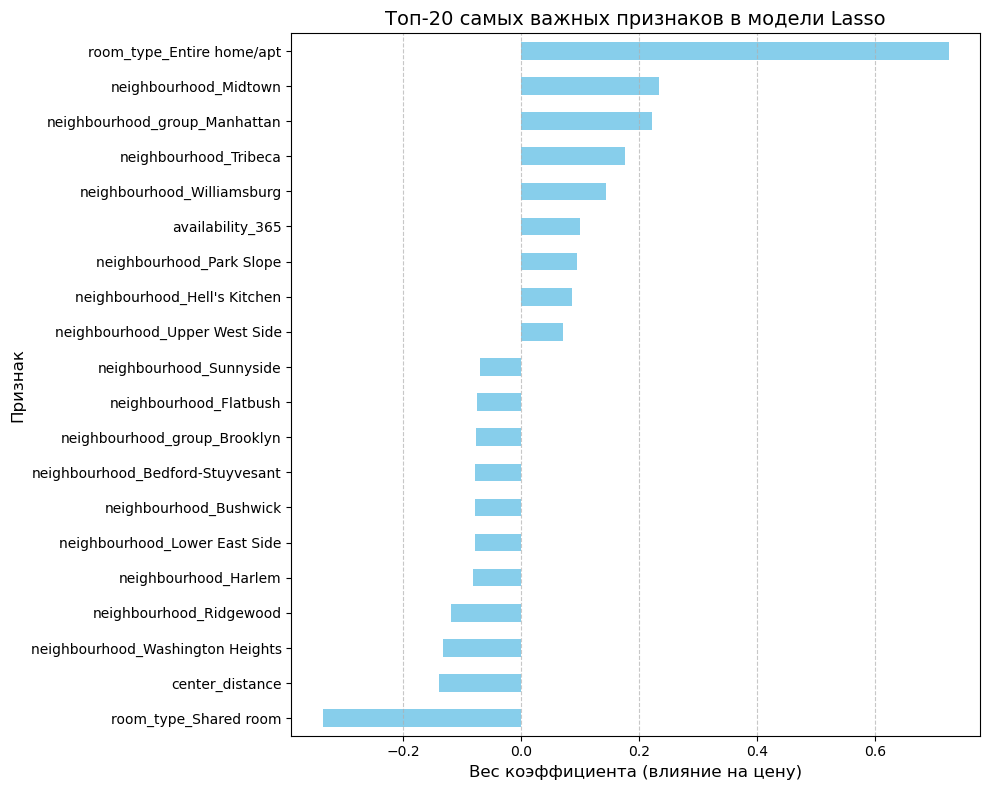

In [77]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': grid_cv_lasso.best_estimator_.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Lasso', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()


In [79]:
print_metrics(y_test, y_pred_lasso)

MAE:  60.60066109713305
RMSE:  219.28067220978394
R2:  0.5194903496308437
MAPE:  37.880996073519775


In [80]:
print_metrics(y_test, y_pred_regr)

MAE:  60.16206411711348
RMSE:  218.0554956956458
R2:  0.5341985174183872
MAPE:  37.39519447305273


In [81]:
from sklearn.linear_model import LassoCV

lasso_cv = LassoCV(cv=5)
lasso_cv.fit(X_train, y_train)
print("Лучшее значение параметра: ", lasso_cv.alpha_)

y_pred_lasso_cv = lasso_cv.predict(X_test)

Лучшее значение параметра:  0.00024640268556420475


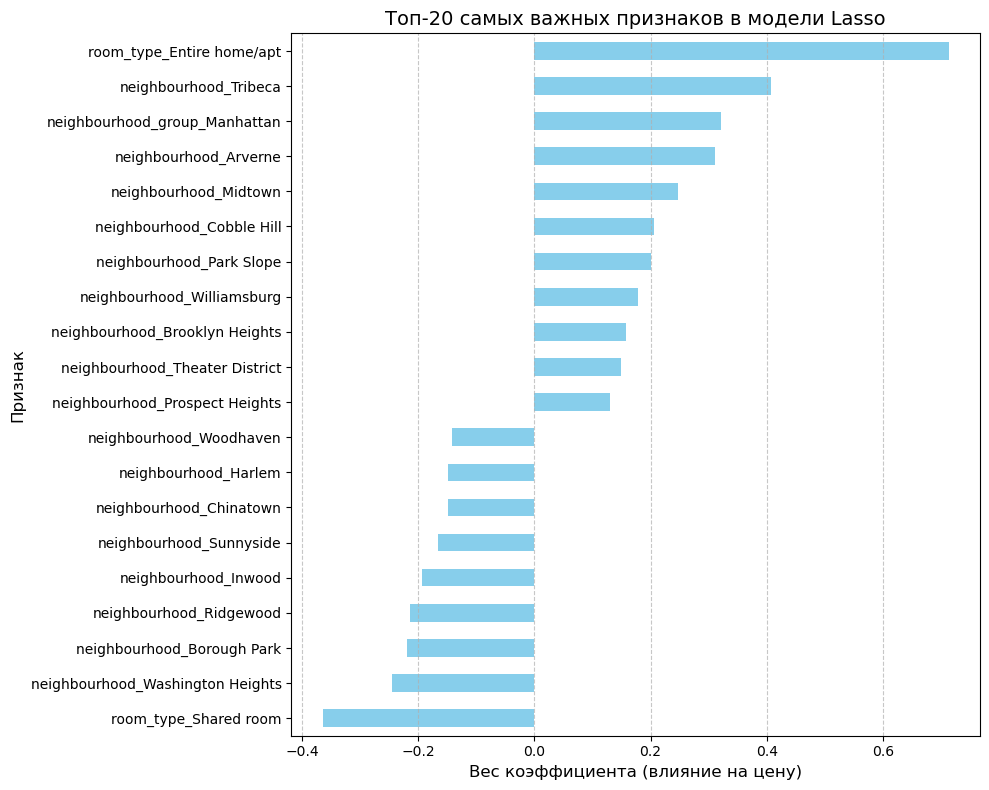

In [83]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': lasso_cv.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Lasso', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()

In [84]:
print_metrics(y_test, y_pred_lasso_cv)

MAE:  60.25415879201521
RMSE:  218.425993593088
R2:  0.5301697701841628
MAPE:  37.519746551633546


# RidgeCV-регрессия

In [85]:
from sklearn.linear_model import RidgeCV

In [86]:
ridge_model = RidgeCV(cv=5)
ridge_model.fit(X_train, y_train)
print("Лучшее значение параметра: ", ridge_model.alpha_)

y_pred_ridge_model = ridge_model.predict(X_test)

Лучшее значение параметра:  10.0


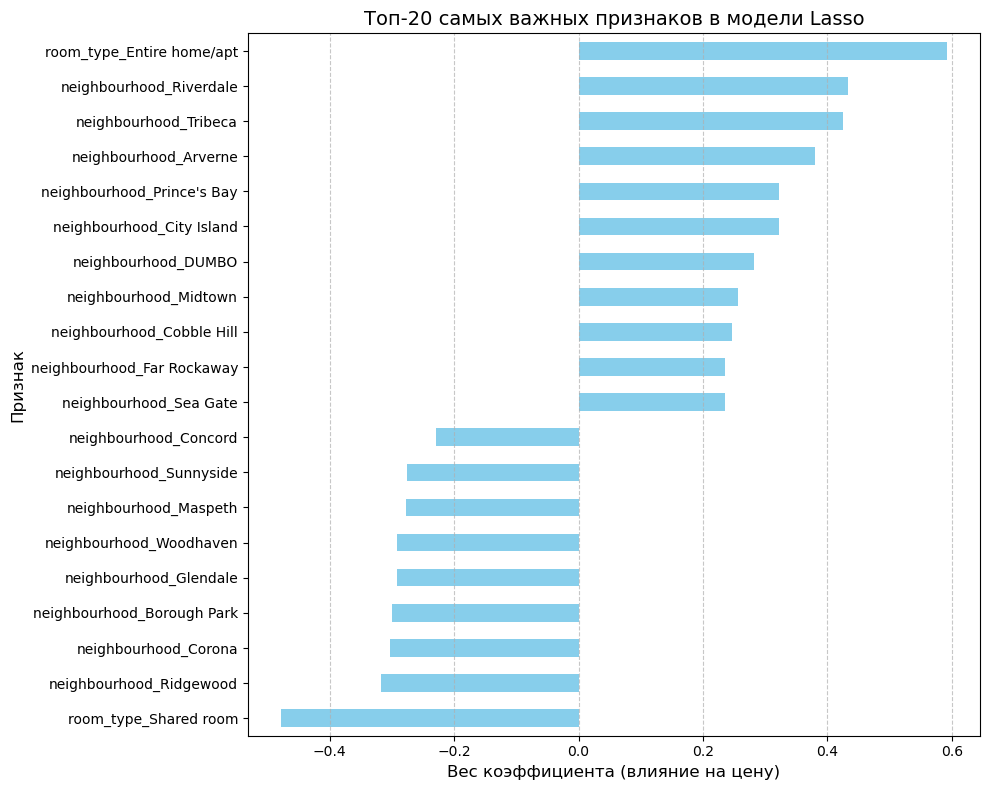

In [87]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': ridge_model.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Lasso', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()

In [88]:
print_metrics(y_test, y_pred_ridge_model)

MAE:  60.12157979561595
RMSE:  218.16622806875773
R2:  0.5345231707607069
MAPE:  37.381137977580394


# ElasticNetCV

In [89]:
from sklearn.linear_model import ElasticNetCV

In [92]:
elastick = ElasticNetCV(cv=5)
elastick.fit(X_train, y_train)
print("Лучшее значение параметра: ", elastick.alpha_)

y_pred_elas = elastick.predict(X_test)

Лучшее значение параметра:  0.0004928053711284095


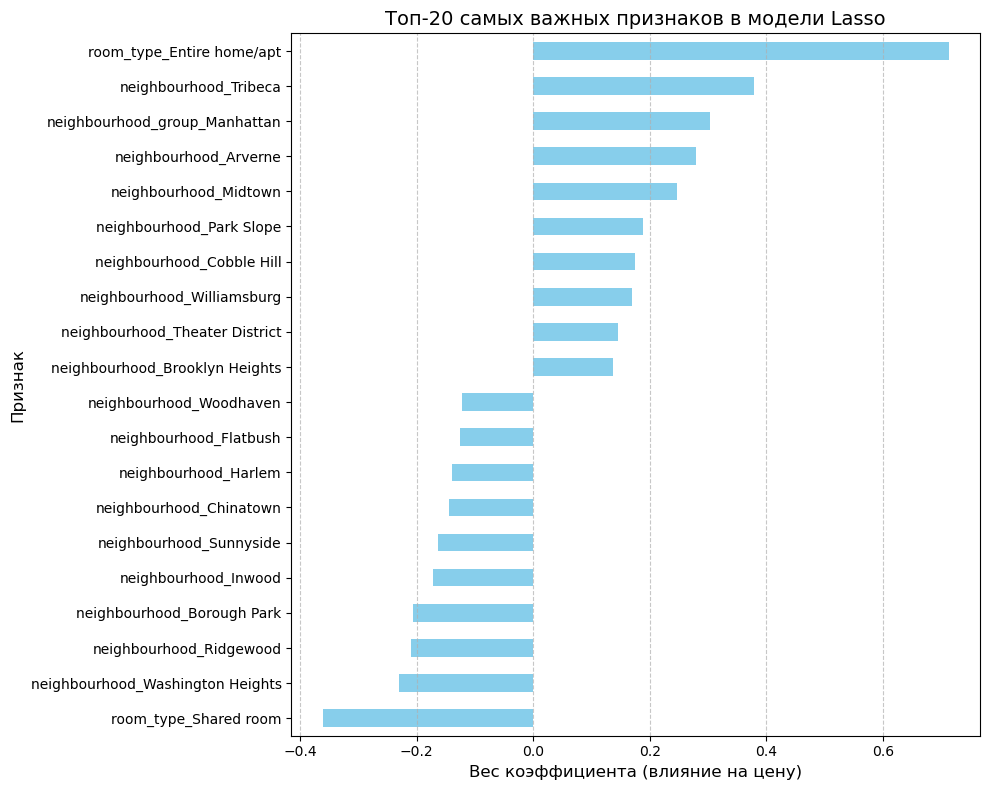

In [93]:
featureImportance = pd.DataFrame({
    'feature': df.drop('price', axis=1).columns,
    'importance': elastick.coef_
}).set_index('feature')

# 2. Считаем абсолютное значение для правильной сортировки (чтобы учесть сильный плюс и сильный минус)
featureImportance['abs_importance'] = featureImportance['importance'].abs()

# 3. Отбираем топ-20 самых влиятельных признаков
top_features = featureImportance.sort_values(by='abs_importance', ascending=False).head(20)

# 4. Сортируем обратно по значению, чтобы на горизонтальном графике они шли от меньшего к большему
top_features = top_features.sort_values(by='importance', ascending=True)

# 5. Строим красивый и читаемый горизонтальный график (barh)
plt.figure(figsize=(10, 8))
top_features['importance'].plot(kind='barh', color='skyblue')


plt.title(f'Топ-20 самых важных признаков в модели Lasso', fontsize=14)
plt.xlabel('Вес коэффициента (влияние на цену)', fontsize=12)
plt.ylabel('Признак', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7) # Сетка только по вертикальным линиям для удобства оценки

plt.tight_layout() # Корректно отобразит длинные названия признаков без обрезания текста
plt.show()

In [94]:
print_metrics(y_test, y_pred_elas)

MAE:  60.253667231050095
RMSE:  218.5000900086838
R2:  0.5297774906029546
MAPE:  37.524866184901306
